# AR identity / mirror diagnostics (notebook 17): what are Transformer AR and Looped AR doing wrong?

**Diagnostic only.**
* Reads the SAVED free-running predictions of the identity-format AR runs: fixed S=5 supports 02/023/0234/02345 and
  the notebook-16 slot-count runs S=2/3/4/6, plus optional variable_length history.
* No training, fine-tuning, re-evaluation or new inputs. CPU is enough.

**Method.**
* Every singleton, the selected same-target controls and all 729,000 six-step records per S=6 model are matched EXACTLY
  to the 288 legal spatial transforms. Ambiguous match sets are kept, never broken arbitrarily.
* Wrong legal outputs are split into extra output-C / extra input-C / other residual classes.
* Also: same-target pairs (A~ACC, B~BCC, C~CCC, C~CCCCC), held-out source-position copying maps, six-step strata by
  number of C tokens, and placement / slot-count / format comparisons.

**Questions answered in the final evidence table.**
1. Is singleton C predicted as identity, another legal transform, or a non-legal grid?
2. Under train023, do A/B failures share an extra-mirror error with C?
3. Can ACC/BCC/CCC be correct while A/B/C fail on the same grid?
4. Do S=6 six-step failures concentrate on odd C count / the wrong mirror class?
5. How do I placement and slot count change these error patterns?
6. Are high-cell / exact-wrong outputs stable wrong copying maps or input-dependent?

These are behavioural descriptions of outputs, NOT mechanistic claims.

**When it finishes, send back `AR_Identity_Diagnostics_Review.ipynb`.** The last cell prints its path and offers a
download. It is a self-contained snapshot with every table and figure baked in.


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 3f7fe9704a915006f7a74a0d88057d2a5799dd1e


In [2]:
# --- CONFIGURATION ------------------------------------------------------------------------------------------------
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
ARTIFACT_ROOTS = [f"{RESULTS_ROOT}/identity_varlen_02345_all_models",     # S=5/train02345 (+ variable_length)
                  f"{RESULTS_ROOT}/identity_ar_count_extrapolation",      # S=5/train02, train023, train0234
                  f"{RESULTS_ROOT}/identity_ar_slot_count"]               # S=2/3/4/6 (notebook 16)
RUN_OVERRIDES = {}   # e.g. {"S5/train02/transformer_ar": "/content/drive/MyDrive/.../eval/transformer_ar/ARTIFACT.json"}
INCLUDE_VARIABLE_LENGTH = True        # optional history; never blocks the core analysis
RECOMPUTE_MISSING_PREDICTIONS = False # no training / re-evaluation is performed by this notebook
MAX_NEW_INFERENCE_RECORDS_PER_RUN = 30000
VERIFY_PREDICTION_SHA = True
NEAREST_PER_WORD = 20                 # six-step nearest-transform subset (stable hash), per word per model
OUT_ROOT = f"{RESULTS_ROOT}/ar_identity_mirror_diagnostics"
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
if RECOMPUTE_MISSING_PREDICTIONS:
    raise NotImplementedError("Bounded re-inference is not implemented in this version; missing sources are reported "
                              "as unavailable instead (no checkpoint is run).")
import pandas as pd
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 120)
from decompositionality.mirror_report import Diagnostics
D = Diagnostics(RESULTS_ROOT, ARTIFACT_ROOTS, RUN_OVERRIDES, OUT_ROOT, INCLUDE_VARIABLE_LENGTH, VERIFY_PREDICTION_SHA,
                NEAREST_PER_WORD)
D.conventions()


Mounted at /content/drive


## 0. Task and group conventions (verified by independent array operations)
* A(X)[r,c]=X[r,(c-1) mod 6], B(X)[r,c]=X[5-c,r], C(X)[r,c]=X[r,5-c], words left to right (AB = B(A(X))). Output-to-source permutations p_g with g(x)=x[p_g]; p_AB = p_A[p_B].
* 288 transforms g = T(dr,dc) o B^r o C^m (mirror first, rotation, translation last), all distinct.
* **Mirror class m = (#C tokens) mod 2**, not the cell-permutation sign (C is an EVEN and B an ODD permutation of the 36 cells).
* Residuals: Delta_out = p_true_inv[p_pred], Delta_in = p_pred[p_true_inv]; extra output-C <=> Delta_out = C (P_hat = C o P); extra input-C <=> Delta_in = C (P_hat = P o C). For the singleton C both equal the identity output (alias kept, never double counted).


### Convention checks


,check,result
0,group_size,288
1,canonical_unique,True
2,AB_is_pA[pB],True
3,orders,"A^6=B^4=C^2=I, A^3!=I"
4,"CAC=A^-1, CBC=B^-1",True
5,mirror_class=#C mod 2 (words k<=6),True
6,cell_permutation_parity,"{'A': 1, 'B': -1, 'C': 1}"
7,residual_formulas,True


In [3]:
# --- 1. Discover runs (read-only) and audit sources -------------------------------------------------------
D.discover()

## 1. Run discovery (read-only) and source audit


### Artifact roots scanned


,root,exists,artifact_files,runs_added
0,/content/drive/MyDrive/decompositionality_results/identity_varlen_02345_all_models,True,18,4
1,/content/drive/MyDrive/decompositionality_results/identity_ar_count_extrapolation,True,4,4
2,/content/drive/MyDrive/decompositionality_results/identity_ar_slot_count,True,8,8



### Run inventory (16 core + 2 optional)


,run_id,role,status,S,train_k,seed,selected_step,config_hash,manifest_hash
0,S5/train02/transformer_ar,core,NOT FOUND in scanned roots (unavailable; not retrained),NaN,nan,NaN,NaN,NaN,NaN
1,S5/train02/looped_transformer_ar,core,NOT FOUND in scanned roots (unavailable; not retrained),NaN,nan,NaN,NaN,NaN,NaN
2,S5/train023/transformer_ar,core,available,5.0,"(0, 2, 3)",42,5000.0,d3779820ef16b598,bdf24c327a65030d53ce376a0aa14447e0cc5887377aceca3555f262874931a8
3,S5/train023/looped_transformer_ar,core,available,5.0,"(0, 2, 3)",42,5000.0,eddb89d069ff44ce,bdf24c327a65030d53ce376a0aa14447e0cc5887377aceca3555f262874931a8
4,S5/train0234/transformer_ar,core,available,5.0,"(0, 2, 3, 4)",42,5000.0,cc1e79289e11312f,bdf24c327a65030d53ce376a0aa14447e0cc5887377aceca3555f262874931a8
5,S5/train0234/looped_transformer_ar,core,available,5.0,"(0, 2, 3, 4)",42,4750.0,2f3743330fd7c05f,bdf24c327a65030d53ce376a0aa14447e0cc5887377aceca3555f262874931a8
6,S5/train02345/transformer_ar,core,available,5.0,"(0, 2, 3, 4, 5)",unknown,5000.0,97011c981c642231,bdf24c327a65030d53ce376a0aa14447e0cc5887377aceca3555f262874931a8
7,S5/train02345/looped_transformer_ar,core,available,5.0,"(0, 2, 3, 4, 5)",unknown,5000.0,82aa67dd7f639d47,bdf24c327a65030d53ce376a0aa14447e0cc5887377aceca3555f262874931a8
8,S2/train02/transformer_ar,core,available,2.0,"(0, 2)",42,5000.0,de6407182ebf92ed,bdf24c327a65030d53ce376a0aa14447e0cc5887377aceca3555f262874931a8
9,S2/train02/looped_transformer_ar,core,available,2.0,"(0, 2)",42,5000.0,5df7958d7eb74987,bdf24c327a65030d53ce376a0aa14447e0cc5887377aceca3555f262874931a8



### Run metadata


,run_id,selection_rule,model_hash,data_version,initialization,expected_records,origin
0,S5/train02/transformer_ar,NaN,NaN,NaN,NaN,NaN,NaN
1,S5/train02/looped_transformer_ar,NaN,NaN,NaN,NaN,NaN,NaN
2,S5/train023/transformer_ar,lowest k-macro validation final-answer digit CE over k in 0/2/3/4/5 (ties -> earlier),b8c7a0906c8420d2,decomp-idext-v1,unknown (not recorded),376000.0,ARTIFACT.json
3,S5/train023/looped_transformer_ar,lowest k-macro validation final-answer digit CE over k in 0/2/3/4/5 (ties -> earlier),76a3940b2ffbff78,decomp-idext-v1,unknown (not recorded),376000.0,ARTIFACT.json
4,S5/train0234/transformer_ar,lowest k-macro validation final-answer digit CE over k in 0/2/3/4/5 (ties -> earlier),b8c7a0906c8420d2,decomp-idext-v1,unknown (not recorded),376000.0,ARTIFACT.json
5,S5/train0234/looped_transformer_ar,lowest k-macro validation final-answer digit CE over k in 0/2/3/4/5 (ties -> earlier),76a3940b2ffbff78,decomp-idext-v1,unknown (not recorded),376000.0,ARTIFACT.json
6,S5/train02345/transformer_ar,lowest k-macro validation final-answer digit CE over k in 0/2/3/4/5 (ties -> earlier),b8c7a0906c8420d2,decomp-idvar02345-v1,unknown (not recorded),376000.0,ARTIFACT.json
7,S5/train02345/looped_transformer_ar,lowest k-macro validation final-answer digit CE over k in 0/2/3/4/5 (ties -> earlier),76a3940b2ffbff78,decomp-idvar02345-v1,unknown (not recorded),376000.0,ARTIFACT.json
8,S2/train02/transformer_ar,"lowest k-macro validation final-answer digit CE (EOS excluded) over k in [0, 2] (ties -> earlier)",2ec390040311cbf5,decomp-idslot-v1,historical S=5 identity init (seed) with position table grown 82->83 rows; added row from a separate generator,16000.0,ARTIFACT.json
9,S2/train02/looped_transformer_ar,"lowest k-macro validation final-answer digit CE (EOS excluded) over k in [0, 2] (ties -> earlier)",149d0fd9035927c4,decomp-idslot-v1,historical S=5 identity init (seed) with position table grown 82->83 rows; added row from a separate generator,16000.0,ARTIFACT.json


Test-manifest hashes across found runs: ['bdf24c327a65030d53ce376a0aa14447e0cc5887377aceca3555f262874931a8'] (one shared manifest).

In [4]:
# --- 2. Load predictions, audits, exact group matching (cached by prediction sha), overview ------------------
D.load()
D.overview()

## 2. Load saved predictions, audit, exact legal-transform matching

  [S5/train023/transformer_ar] 23,000 diagnostic records (matched) in 2.7s
  [S5/train023/looped_transformer_ar] 23,000 diagnostic records (matched) in 2.2s
  [S5/train0234/transformer_ar] 23,000 diagnostic records (matched) in 2.2s
  [S5/train0234/looped_transformer_ar] 23,000 diagnostic records (matched) in 2.1s
  [S5/train02345/transformer_ar] 23,000 diagnostic records (matched) in 2.3s
  [S5/train02345/looped_transformer_ar] 23,000 diagnostic records (matched) in 3.4s
  [S2/train02/transformer_ar] 8,000 diagnostic records (matched) in 0.3s
  [S2/train02/looped_transformer_ar] 8,000 diagnostic records (matched) in 0.3s
  [S3/train023/transformer_ar] 14,000 diagnostic records (matched) in 0.4s
  [S3/train023/looped_transformer_ar] 14,000 diagnostic records (matched) in 0.4s
  [S4/train0234/transformer_ar] 19,000 diagnostic records (matched) in 0.8s
  [S4/train0234/looped_transformer_ar] 19,000 diagnostic records (matched) in 0.8s
  [S6/train02345/transformer_ar] 755,000 diagnostic re

,run_id,records,expected_records,count_ok,duplicate_keys,oracle_target_mismatches,grid_hash_mismatches,stored_exact_mismatches,invalid_records,invalid_coded_as_minus1,perfect_predictor_exact,singleton_records,k6_records,decoding,label_spans,ok,matching,seconds
0,S5/train023/transformer_ar,376000,376000,True,0,0,0,0,4,True,1.0,15000,0,greedy free-running from prefix through OUTPUT (evaluate_idvar_model),36 answer digits + EOS after OUTPUT (ARLayout; verified in notebook 16 layout audit),True,computed,2.7
1,S5/train023/looped_transformer_ar,376000,376000,True,0,0,0,0,0,True,1.0,15000,0,greedy free-running from prefix through OUTPUT (evaluate_idvar_model),36 answer digits + EOS after OUTPUT (ARLayout; verified in notebook 16 layout audit),True,computed,2.2
2,S5/train0234/transformer_ar,376000,376000,True,0,0,0,0,0,True,1.0,15000,0,greedy free-running from prefix through OUTPUT (evaluate_idvar_model),36 answer digits + EOS after OUTPUT (ARLayout; verified in notebook 16 layout audit),True,computed,2.2
3,S5/train0234/looped_transformer_ar,376000,376000,True,0,0,0,0,0,True,1.0,15000,0,greedy free-running from prefix through OUTPUT (evaluate_idvar_model),36 answer digits + EOS after OUTPUT (ARLayout; verified in notebook 16 layout audit),True,computed,2.1
4,S5/train02345/transformer_ar,376000,376000,True,0,0,0,0,0,True,1.0,15000,0,greedy free-running from prefix through OUTPUT (evaluate_idvar_model),36 answer digits + EOS after OUTPUT (ARLayout; verified in notebook 16 layout audit),True,computed,2.3
5,S5/train02345/looped_transformer_ar,376000,376000,True,0,0,0,0,0,True,1.0,15000,0,greedy free-running from prefix through OUTPUT (evaluate_idvar_model),36 answer digits + EOS after OUTPUT (ARLayout; verified in notebook 16 layout audit),True,computed,3.4
6,S2/train02/transformer_ar,16000,16000,True,0,0,0,0,0,True,1.0,6000,0,greedy free-running from prefix through OUTPUT (evaluate_idvar_model),36 answer digits + EOS after OUTPUT (ARLayout; verified in notebook 16 layout audit),True,computed,0.3
7,S2/train02/looped_transformer_ar,16000,16000,True,0,0,0,0,0,True,1.0,6000,0,greedy free-running from prefix through OUTPUT (evaluate_idvar_model),36 answer digits + EOS after OUTPUT (ARLayout; verified in notebook 16 layout audit),True,computed,0.3
8,S3/train023/transformer_ar,46000,46000,True,0,0,0,0,0,True,1.0,9000,0,greedy free-running from prefix through OUTPUT (evaluate_idvar_model),36 answer digits + EOS after OUTPUT (ARLayout; verified in notebook 16 layout audit),True,computed,0.4
9,S3/train023/looped_transformer_ar,46000,46000,True,0,0,0,0,0,True,1.0,9000,0,greedy free-running from prefix through OUTPUT (evaluate_idvar_model),36 answer digits + EOS after OUTPUT (ARLayout; verified in notebook 16 layout audit),True,computed,0.4



### Reconciliation with user-reported counts (reported values are NOT used as results)


,run_id,quantity,reported,observed,delta,status,selected_step
0,S2/train02/transformer_ar,singleton,0/6000,0/6000,0,match,5000
1,S2/train02/looped_transformer_ar,singleton,0/6000,0/6000,0,match,5000
2,S3/train023/transformer_ar,singleton,0/9000,0/9000,0,match,4500
3,S3/train023/looped_transformer_ar,singleton,0/9000,0/9000,0,match,5000
4,S5/train023/transformer_ar,singleton,0/15000,0/15000,0,match,5000
5,S5/train023/looped_transformer_ar,singleton,0/15000,0/15000,0,match,5000
6,S4/train0234/transformer_ar,singleton,12000/12000,12000/12000,0,match,5000
7,S4/train0234/looped_transformer_ar,singleton,0/12000,0/12000,0,match,4750
8,S5/train0234/transformer_ar,singleton,3796/15000,3796/15000,0,match,5000
9,S5/train0234/looped_transformer_ar,singleton,0/15000,0/15000,0,match,4750


## Overview


### Overview of analysed runs (full-population exact counts)


,run_id,S,train_k,singleton exact,A,B,C,k6 exact,selected_step
0,S5/train023/transformer_ar,5.0,"(0, 2, 3)",0/15000,0/5000,0/5000,0/5000,N/A,5000
1,S5/train023/looped_transformer_ar,5.0,"(0, 2, 3)",0/15000,0/5000,0/5000,0/5000,N/A,5000
2,S5/train0234/transformer_ar,5.0,"(0, 2, 3, 4)",3796/15000,278/5000,3518/5000,0/5000,N/A,5000
3,S5/train0234/looped_transformer_ar,5.0,"(0, 2, 3, 4)",0/15000,0/5000,0/5000,0/5000,N/A,4750
4,S5/train02345/transformer_ar,5.0,"(0, 2, 3, 4, 5)",15000/15000,5000/5000,5000/5000,5000/5000,N/A,5000
5,S5/train02345/looped_transformer_ar,5.0,"(0, 2, 3, 4, 5)",14858/15000,5000/5000,4998/5000,4860/5000,N/A,5000
6,S2/train02/transformer_ar,2.0,"(0, 2)",0/6000,0/2000,0/2000,0/2000,N/A,5000
7,S2/train02/looped_transformer_ar,2.0,"(0, 2)",0/6000,0/2000,0/2000,0/2000,N/A,5000
8,S3/train023/transformer_ar,3.0,"(0, 2, 3)",0/9000,0/3000,0/3000,0/3000,N/A,4500
9,S3/train023/looped_transformer_ar,3.0,"(0, 2, 3)",0/9000,0/3000,0/3000,0/3000,N/A,5000


## 3. Singleton diagnostics (held out in every run)
Outcome categories are disjoint. Hypothesis match counts (identity / true / extra output-C / extra input-C) can OVERLAP; for X=C the two extra-C hypotheses and identity are the same transform (alias).


### Singleton outcomes by run x operation (disjoint outcome columns sum to n)


,run_id,op,n,correct,wrong: invalid output,"wrong: valid, no legal match","wrong: valid, unique legal transform","wrong: valid, multiple legal transforms",correct but ambiguous transform
0,S5/train023/transformer_ar,A,5000,0,4,4996,0,0,0
1,S5/train023/transformer_ar,B,5000,0,0,5000,0,0,0
2,S5/train023/transformer_ar,C,5000,0,0,0,5000,0,0
3,S5/train023/looped_transformer_ar,A,5000,0,0,4977,23,0,0
4,S5/train023/looped_transformer_ar,B,5000,0,0,5000,0,0,0
5,S5/train023/looped_transformer_ar,C,5000,0,0,0,5000,0,0
6,S5/train0234/transformer_ar,A,5000,278,0,4722,0,0,0
7,S5/train0234/transformer_ar,B,5000,3518,0,1482,0,0,0
8,S5/train0234/transformer_ar,C,5000,0,0,0,5000,0,0
9,S5/train0234/looped_transformer_ar,A,5000,0,0,5000,0,0,0



### Wrong legal singleton predictions: hypothesis matches (overlapping) and residual classes (disjoint)


,run_id,op,wrong legal: identity,wrong legal: extra out-C,wrong legal: extra in-C,"wrong legal: union(out-C, in-C)",residual: extra output-C only,residual: extra input-C only,residual: both extra-C hypotheses,residual: other orientation-reversing,residual: orientation-preserving nonidentity,residual: ambiguous residual
0,S5/train023/transformer_ar,A,0,0,0,0,0,0,0,0,0,0
1,S5/train023/transformer_ar,B,0,0,0,0,0,0,0,0,0,0
2,S5/train023/transformer_ar,C,5000,5000,5000,5000,0,0,5000,0,0,0
3,S5/train023/looped_transformer_ar,A,0,0,0,0,0,0,0,0,23,0
4,S5/train023/looped_transformer_ar,B,0,0,0,0,0,0,0,0,0,0
5,S5/train023/looped_transformer_ar,C,5000,5000,5000,5000,0,0,5000,0,0,0
6,S5/train0234/transformer_ar,A,0,0,0,0,0,0,0,0,0,0
7,S5/train0234/transformer_ar,B,0,0,0,0,0,0,0,0,0,0
8,S5/train0234/transformer_ar,C,5000,5000,5000,5000,0,0,5000,0,0,0
9,S5/train0234/looped_transformer_ar,A,0,0,0,0,0,0,0,0,0,0



### Singleton by operation x position (first 120 of 186 rows; full table in CSV export)


... (2 outputs left out)

,run_id,op,position,exact,top_wrong_unique_transforms,top_residual_delta_out
0,S5/train023/transformer_ar,A,1,0/1000,,
1,S5/train023/transformer_ar,A,2,0/1000,,
2,S5/train023/transformer_ar,A,3,0/1000,,
3,S5/train023/transformer_ar,A,4,0/1000,,
4,S5/train023/transformer_ar,A,5,0/1000,,
...,...,...,...,...,...,...
102,S3/train023/transformer_ar,A,1,0/1000,,
103,S3/train023/transformer_ar,A,2,0/1000,,
104,S3/train023/transformer_ar,A,3,0/1000,"T(0,1) o C (577)","T(0,2) o C (577)"
105,S3/train023/transformer_ar,B,1,0/1000,,



### Singletons: true geometric mirror class vs predicted (ambiguous / no legal match / invalid kept)


pred_mirror,run_id,word,true_mirror,0,1,invalid,no legal match
0,S2/train02/looped_transformer_ar,A,0,0,1133,0,867
1,S2/train02/looped_transformer_ar,B,0,0,595,0,1405
2,S2/train02/looped_transformer_ar,C,1,2000,0,0,0
3,S2/train02/transformer_ar,A,0,0,1972,0,28
4,S2/train02/transformer_ar,B,0,0,1326,0,674
5,S2/train02/transformer_ar,C,1,2000,0,0,0
6,S3/train023/looped_transformer_ar,A,0,0,12,0,2988
7,S3/train023/looped_transformer_ar,B,0,0,0,0,3000
8,S3/train023/looped_transformer_ar,C,1,3000,0,0,0
9,S3/train023/transformer_ar,A,0,0,577,0,2423



### Singleton exact-grid accuracy heatmaps


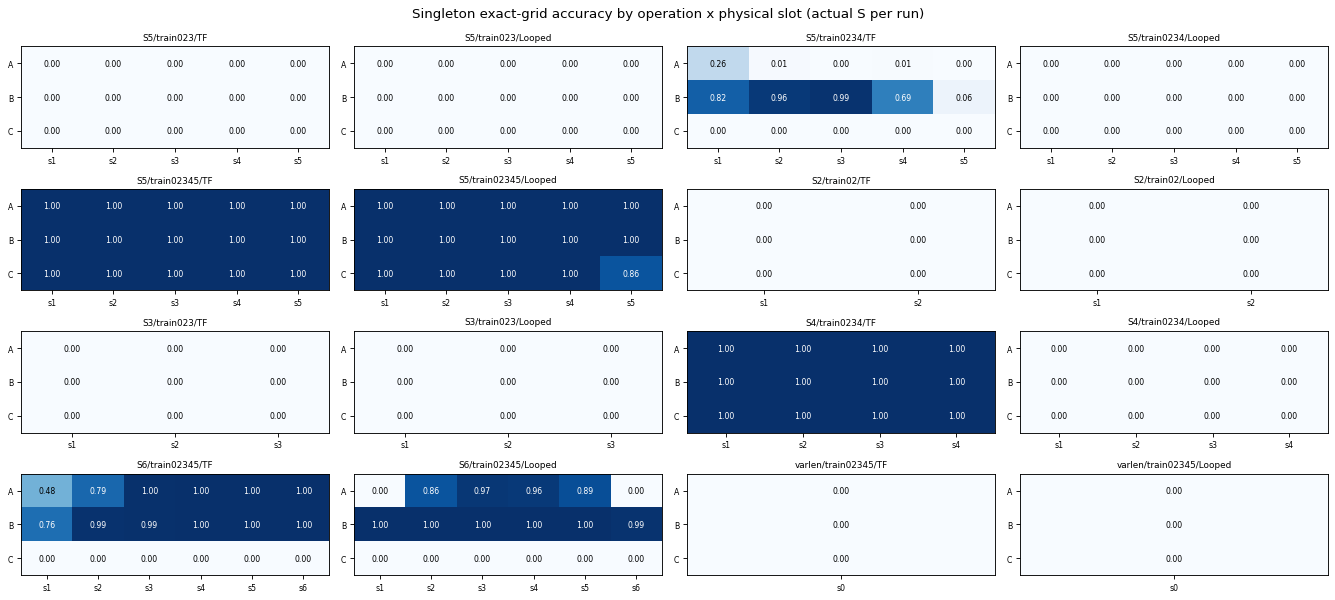


### Singleton cell accuracy heatmaps


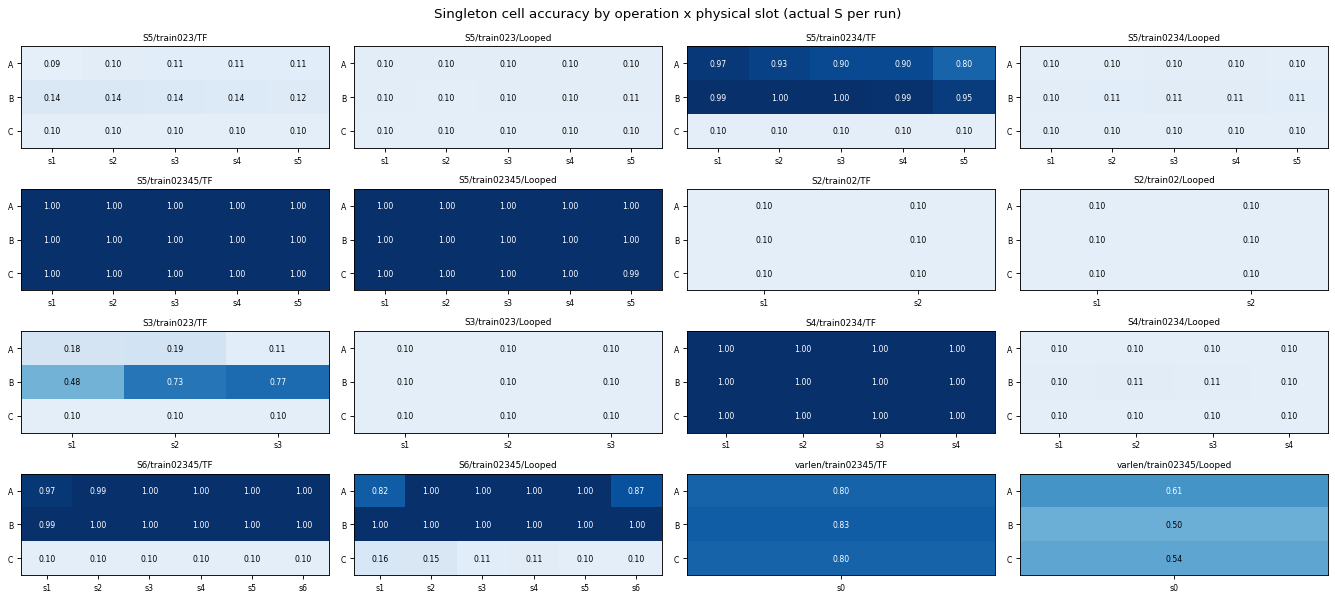


### Singleton outcome categories


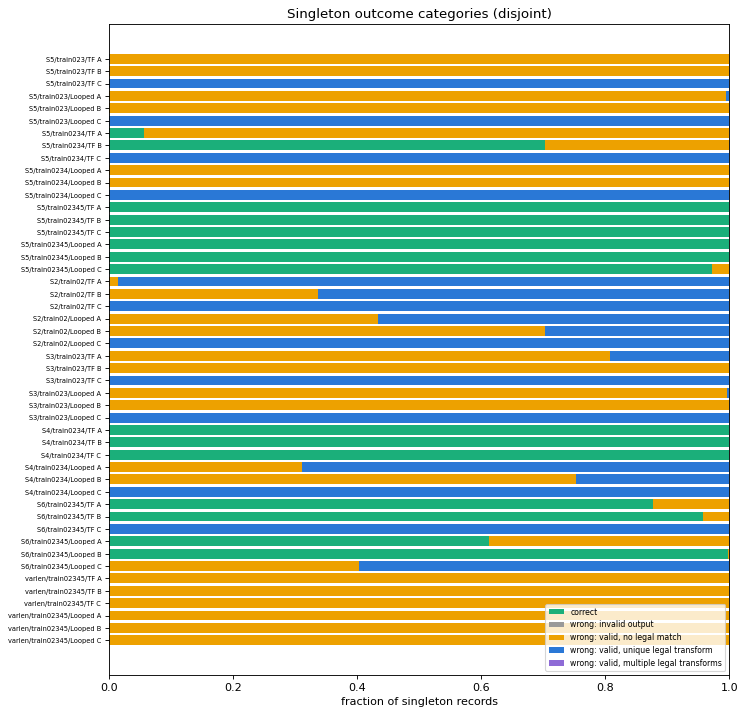


### Singleton residual classes


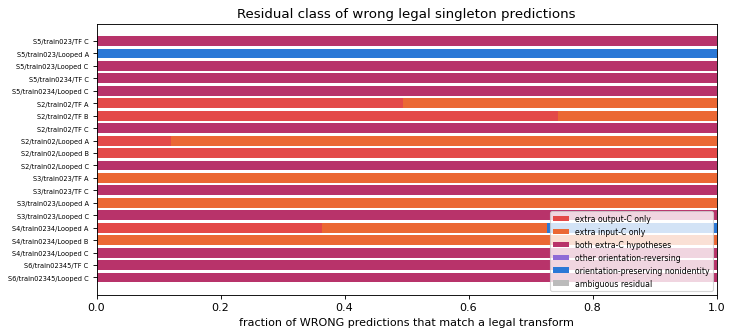


### Singleton mirror-class confusion


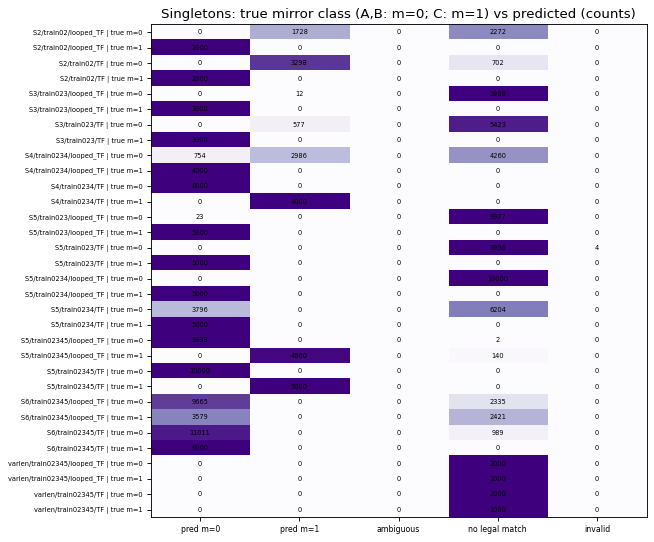


### Per-cell accuracy maps and wrong-cell counts for selected failing singleton groups


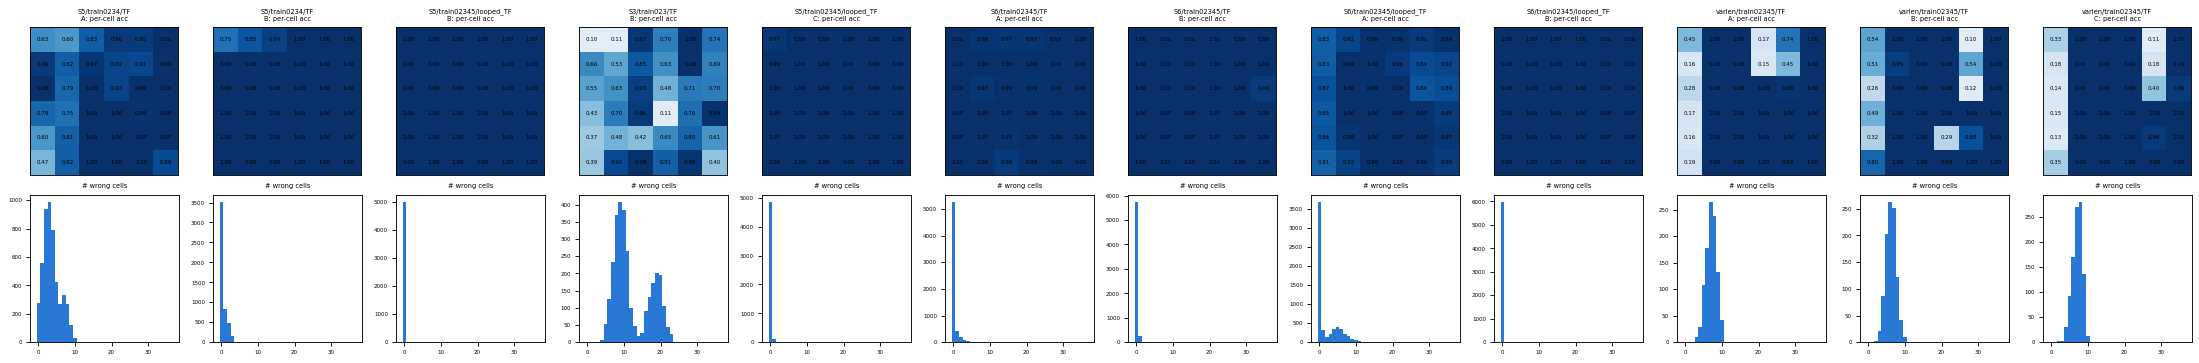


### Spatial error profile of selected failing singleton groups (first wrong cell is descriptive only)


,run_id,op,records,mean_wrong_cells,records_with_1-3_wrong_cells,records_with_>=30_wrong_cells,per-cell acc min/median/max,"first wrong generated cell (top, descriptive)"
0,S5/train0234/transformer_ar,A,5000,3.646000,2479,0,0.47/0.97/1.00,0 (1827); 1 (1547); 30 (439); 24 (220)
1,S5/train0234/transformer_ar,B,5000,0.456800,1482,0,0.75/1.00/1.00,0 (1238); 1 (215); 2 (28); 30 (1)
2,S5/train02345/looped_transformer_ar,B,5000,0.000400,2,0,1.00/1.00/1.00,32 (2)
3,S3/train023/transformer_ar,B,3000,12.256667,1,0,0.10/0.69/1.00,0 (2712); 1 (256); 7 (12); 3 (10)
4,S5/train02345/looped_transformer_ar,C,5000,0.036200,137,0,0.97/1.00/1.00,0 (127); 6 (11); 12 (2)
5,S6/train02345/transformer_ar,A,6000,0.213167,683,0,0.96/1.00/1.00,13 (163); 2 (149); 32 (141); 1 (118)
6,S6/train02345/transformer_ar,B,6000,0.043167,254,0,0.96/1.00/1.00,17 (228); 11 (26)
7,S6/train02345/looped_transformer_ar,A,6000,1.865000,681,0,0.81/0.98/1.00,0 (1035); 10 (308); 6 (200); 16 (170)
8,S6/train02345/looped_transformer_ar,B,6000,0.003000,14,0,1.00/1.00/1.00,33 (3); 0 (3); 5 (3); 27 (1)
9,varlen/train02345/transformer_ar,A,1000,7.103000,11,0,0.15/1.00/1.00,0 (548); 3 (371); 6 (61); 9 (11)


In [5]:
# --- 3. Singleton diagnostics -----------------------------------------------------------------------------
D.singletons()

In [6]:
# --- 4. Same-target comparisons (A~ACC, B~BCC, C~CCC, C~CCCCC) and identity controls ----------------------
D.equivalence()

## 4. Same-target instruction comparisons (same input grids)
Singletons have S placements per grid, the composite one saved layout per grid; per-position rows plus a within-grid summary (grids are the unit; positions are not independent replications). These comparisons change word, k and I layout together; they are not causal interventions on I.


### Same-target pairs per singleton position (A~ACC, B~BCC, C~CCC, C~CCCCC) (first 120 of 230 rows; full table in CSV export)


,run_id,singleton,composite,composite_in_training_support,position,paired_grids,targets_identical,composite correct / singleton wrong,both correct,singleton correct / composite wrong,both wrong,exact prediction agreement,singleton outcome when composite correct & singleton wrong,singleton residual (same subset),status
0,S5/train023/transformer_ar,A,ACC,True,1,1000.0,1000.0,1000.0,0.0,0.0,0.0,0.0,"wrong: valid, no legal match (1000)",,NaN
1,S5/train023/transformer_ar,A,ACC,True,2,1000.0,1000.0,1000.0,0.0,0.0,0.0,0.0,"wrong: valid, no legal match (1000)",,NaN
2,S5/train023/transformer_ar,A,ACC,True,3,1000.0,1000.0,1000.0,0.0,0.0,0.0,0.0,"wrong: valid, no legal match (999); wrong: invalid output (1)",,NaN
3,S5/train023/transformer_ar,A,ACC,True,4,1000.0,1000.0,1000.0,0.0,0.0,0.0,0.0,"wrong: valid, no legal match (1000)",,NaN
4,S5/train023/transformer_ar,A,ACC,True,5,1000.0,1000.0,1000.0,0.0,0.0,0.0,0.0,"wrong: valid, no legal match (997); wrong: invalid output (3)",,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,S5/train02345/looped_transformer_ar,C,CCCCC,True,1,1000.0,1000.0,1.0,999.0,0.0,0.0,999.0,"wrong: valid, no legal match (1)",,NaN
116,S5/train02345/looped_transformer_ar,C,CCCCC,True,2,1000.0,1000.0,0.0,1000.0,0.0,0.0,1000.0,,,NaN
117,S5/train02345/looped_transformer_ar,C,CCCCC,True,3,1000.0,1000.0,0.0,1000.0,0.0,0.0,1000.0,,,NaN
118,S5/train02345/looped_transformer_ar,C,CCCCC,True,4,1000.0,1000.0,0.0,1000.0,0.0,0.0,1000.0,,,NaN



### Same-target pairs: within-grid summary (grid = unit)


,run_id,singleton,composite,composite_in_training_support,grids,composite correct,mean singleton acc | composite correct,mean singleton acc | composite wrong,grids: composite correct & singleton wrong at ALL positions,grids: composite correct & singleton correct at ALL positions,grids: composite wrong & singleton correct at ALL positions
0,S5/train023/transformer_ar,A,ACC,True,1000,1000,0.000000,NaN,1000,0,0
1,S5/train023/transformer_ar,B,BCC,True,1000,1000,0.000000,NaN,1000,0,0
2,S5/train023/transformer_ar,C,CCC,True,1000,1000,0.000000,NaN,1000,0,0
3,S5/train023/transformer_ar,C,CCCCC,False,1000,2,0.000000,0.0,2,0,0
4,S5/train023/looped_transformer_ar,A,ACC,True,1000,1000,0.000000,NaN,1000,0,0
5,S5/train023/looped_transformer_ar,B,BCC,True,1000,1000,0.000000,NaN,1000,0,0
6,S5/train023/looped_transformer_ar,C,CCC,True,1000,1000,0.000000,NaN,1000,0,0
7,S5/train023/looped_transformer_ar,C,CCCCC,False,1000,0,NaN,0.0,0,0,0
8,S5/train0234/transformer_ar,A,ACC,True,1000,1000,0.055600,NaN,734,0,0
9,S5/train0234/transformer_ar,B,BCC,True,1000,1000,0.703600,NaN,14,55,0



### Identity-target controls (EMPTY, CC, CCCC, BBBB; S=6 held-out AAAAAA, CCCCCC)


,run_id,word,k,kind,in_training_support,exact,exact_acc,wrong outcome (top)
0,S5/train023/transformer_ar,EMPTY,0,seen,True,1000/1000,1.000,
1,S5/train023/transformer_ar,CC,2,seen,True,1000/1000,1.000,
2,S5/train023/transformer_ar,CCCC,4,seen,False,0/1000,0.000,"wrong: valid, unique legal transform (980); wrong: valid, no legal match (20)"
3,S5/train023/transformer_ar,BBBB,4,seen,False,0/1000,0.000,"wrong: valid, unique legal transform (920); wrong: valid, no legal match (80)"
4,S5/train023/looped_transformer_ar,EMPTY,0,seen,True,1000/1000,1.000,
5,S5/train023/looped_transformer_ar,CC,2,seen,True,1000/1000,1.000,
6,S5/train023/looped_transformer_ar,CCCC,4,seen,False,0/1000,0.000,"wrong: valid, no legal match (654); wrong: valid, unique legal transform (346)"
7,S5/train023/looped_transformer_ar,BBBB,4,seen,False,0/1000,0.000,"wrong: valid, unique legal transform (700); wrong: valid, no legal match (300)"
8,S5/train0234/transformer_ar,EMPTY,0,seen,True,1000/1000,1.000,
9,S5/train0234/transformer_ar,CC,2,seen,True,1000/1000,1.000,


In [7]:
# --- 5. Held-out source-position copying maps ---------------------------------------------------------------
D.source_maps()

## 5. Fixed source-position copying maps (post-hoc, descriptive)
Fit on a fixed 500-grid half (diagnostic_split seed 20251106, same split for every run), evaluated on the other 500 grids, using the group's FULL prediction population (invalid predictions count as mismatches). Ties: point map uses the lowest source index; tied cells are counted. Not evidence of an internal copying circuit.


### Source maps for singleton groups with failures (held-out fidelity) (first 120 of 137 rows; full table in CSV export)


,run_id,op,position,exact_acc,cell_acc,fit_records,eval_records,fit_support_mean,cells_with_tied_sources,bijective,distinct_sources,legal_transform,legal_id,heldout_exact_fidelity,heldout_cell_fidelity
0,S5/train023/transformer_ar,A,1,0.000,0.088889,500,500,0.765556,0,False,27,not legal,-1,0.000,0.764278
1,S5/train023/transformer_ar,A,2,0.000,0.102000,500,500,0.784444,0,False,30,not legal,-1,0.000,0.781500
2,S5/train023/transformer_ar,A,3,0.000,0.106222,500,500,0.831278,0,False,31,not legal,-1,0.000,0.826667
3,S5/train023/transformer_ar,A,4,0.000,0.105944,500,500,0.817556,0,False,31,not legal,-1,0.000,0.815389
4,S5/train023/transformer_ar,A,5,0.000,0.108778,500,500,0.774722,0,False,28,not legal,-1,0.000,0.776889
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,S6/train02345/transformer_ar,C,5,0.000,0.099111,500,500,1.000000,0,True,36,I,0,1.000,1.000000
116,S6/train02345/transformer_ar,C,6,0.000,0.099111,500,500,1.000000,0,True,36,I,0,1.000,1.000000
117,S6/train02345/looped_transformer_ar,A,1,0.000,0.824278,500,500,0.899111,0,False,31,not legal,-1,0.020,0.903778
118,S6/train02345/looped_transformer_ar,A,2,0.861,0.995667,500,500,0.995778,0,True,36,"T(0,1)",1,0.862,0.995556


## 6. S=6 six-operation diagnosis (all 729 words x 1000 grids per model)
Strata differ in A/B composition and word structure; differences are descriptive, not causal effects of C or novelty. One C inside a longer word WAS trained; what was held out is total non-identity count 1 (and 6).


### Recomputed stratum sizes (records = words x 1000)


,check,value
0,training transforms,111
1,six-op words seen-transform / unseen,591/138
2,words by n_C,"[64, 192, 240, 160, 60, 12, 1]"
3,expected,"[64, 192, 240, 160, 60, 12, 1]"



### Six-step strata by number of C tokens


,run_id,n_C,mirror parity,words,records,exact,exact_acc,cell_acc,invalid_rate,legal_coverage,mirror_identifiable_coverage,wrong & mirror correct (identifiable),wrong & mirror WRONG (identifiable),"wrong, mirror ambiguous","wrong, no legal match","wrong, invalid","per-word acc median [min,max]",dominant residuals (unique wrong)
0,S6/train02345/transformer_ar,0,even,64,64000,33376/64000,0.521500,0.880812,0.008141,0.521516,0.521516,1,0,0,30102,521,"0.550 [0.000,1.000]",B^3 (1)
1,S6/train02345/transformer_ar,1,odd,192,192000,101087/192000,0.526495,0.882010,0.002677,0.526505,0.526505,0,2,0,90397,514,"0.690 [0.000,1.000]","T(0,2) o C (1); C (1)"
2,S6/train02345/transformer_ar,2,even,240,240000,127740/240000,0.532250,0.860503,0.000067,0.535446,0.535446,0,767,0,111477,16,"0.679 [0.000,1.000]","T(0,2) o C (754); B^2 o C (10); T(0,4) o C (3)"
3,S6/train02345/transformer_ar,3,odd,160,160000,65842/160000,0.411513,0.814354,0.000006,0.441631,0.441631,0,4819,0,89338,1,"0.114 [0.000,1.000]","C (2881); T(0,4) o C (1938)"
4,S6/train02345/transformer_ar,4,even,60,60000,13512/60000,0.225200,0.638483,0.000000,0.273167,0.273167,0,2878,0,43610,0,"0.000 [0.000,1.000]",C (1879); B^2 o C (999)
5,S6/train02345/transformer_ar,5,odd,12,12000,664/12000,0.055333,0.406671,0.000000,0.097667,0.097667,0,508,0,10828,0,"0.000 [0.000,0.598]",C (287); B^2 o C (221)
6,S6/train02345/transformer_ar,6,even,1,1000,0/1000,0.000000,0.105472,0.000000,0.492000,0.492000,0,492,0,508,0,"0.000 [0.000,0.000]",C (492)
7,S6/train02345/looped_transformer_ar,0,even,64,64000,13009/64000,0.203266,0.829276,0.000000,0.203266,0.203266,0,0,0,50991,0,"0.052 [0.000,0.980]",
8,S6/train02345/looped_transformer_ar,1,odd,192,192000,45057/192000,0.234672,0.803512,0.000000,0.234687,0.234687,3,0,0,146940,0,"0.047 [0.000,0.993]","T(0,5) (3)"
9,S6/train02345/looped_transformer_ar,2,even,240,240000,50149/240000,0.208954,0.753933,0.000000,0.212375,0.212375,784,37,0,189030,0,"0.010 [0.000,0.995]","T(0,1) (784); B^2 o C (36); T(0,2) o C (1)"



### Six-step: n_C parity x target transform in training support


... (4 outputs left out)

,run_id,check,failed,matches
0,S6/train02345/transformer_ar,first five,386779,5540
1,S6/train02345/transformer_ar,last five,386779,3371
2,S6/train02345/transformer_ar,delete op 1,386779,3371
3,S6/train02345/transformer_ar,delete op 2,386779,2073
4,S6/train02345/transformer_ar,delete op 3,386779,3555
5,S6/train02345/transformer_ar,delete op 4,386779,6933
6,S6/train02345/transformer_ar,delete op 5,386779,5493
7,S6/train02345/transformer_ar,delete op 6,386779,5540
8,S6/train02345/transformer_ar,UNION (each record once),386779,9467
9,S6/train02345/looped_transformer_ar,first five,591840,3460



### Mirror evidence side by side


,run_id,group,records,exact_acc,mirror wrong (all records),mirror wrong | identifiable,identifiable coverage
0,S6/train02345/transformer_ar,singleton C,6000,0.000000,1.000000,1.000000,1.000000
1,S6/train02345/transformer_ar,seen CCC,1000,1.000000,0.000000,0.000000,1.000000
2,S6/train02345/transformer_ar,seen CCCCC,1000,0.989000,0.000000,0.000000,0.989000
3,S6/train02345/transformer_ar,"six-step mixed odd-C (n_C 1,3,5)",364000,0.460420,0.014640,0.030817,0.475060
4,S6/train02345/transformer_ar,"six-step even-C (n_C 0,2,4,6)",365000,0.478433,0.011334,0.023142,0.489770
5,S6/train02345/looped_transformer_ar,singleton C,6000,0.000000,0.596500,1.000000,0.596500
6,S6/train02345/looped_transformer_ar,seen CCC,1000,1.000000,0.000000,0.000000,1.000000
7,S6/train02345/looped_transformer_ar,seen CCCCC,1000,0.997000,0.000000,0.000000,0.997000
8,S6/train02345/looped_transformer_ar,"six-step mixed odd-C (n_C 1,3,5)",364000,0.196047,0.006121,0.030204,0.202648
9,S6/train02345/looped_transformer_ar,"six-step even-C (n_C 0,2,4,6)",365000,0.180271,0.004362,0.023352,0.186781



### Six-step accuracy and mirror errors by n_C


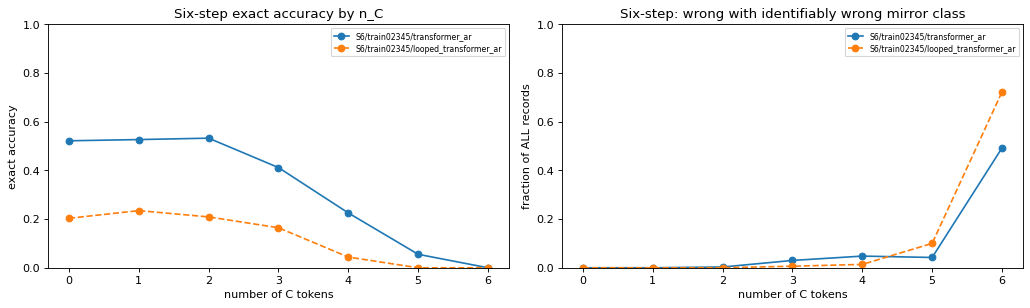


### Six-step example gallery


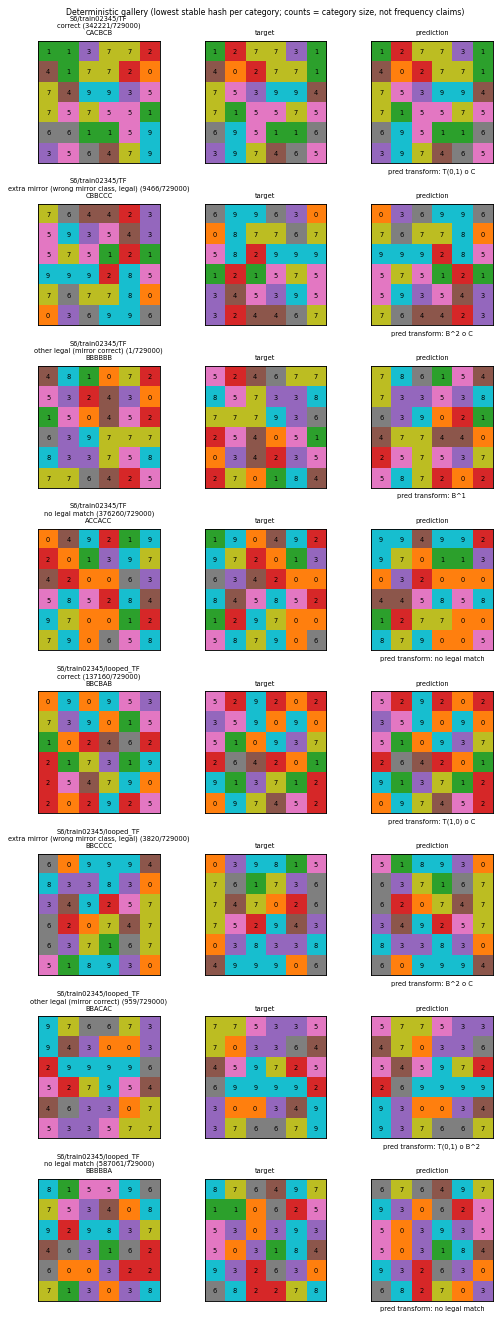

In [8]:
# --- 6. S=6 six-operation diagnosis ------------------------------------------------------------------------
D.six_step()

In [9]:
# --- 7. Placement / slot-count / optional format comparisons -------------------------------------------------
D.comparisons()

## 7. Placement, slot-count and format comparisons
(i) fixed visible-I vs genuinely variable-length input and (ii) fixed-slot designs with vs without zero-I training instructions are kept separate. At fixed S, n_I = S - k is determined by k; no separate causal effects are estimated.


### Placement invariance within each run (agreement separate from correctness)


,run_id,op,positions,mean_acc,min_acc,max_acc,grids all positions correct,grids identical prediction across positions,grids all positions wrong
0,S5/train023/transformer_ar,A,5,0.000000,0.000,0.000,0.000,0.000,1.000
1,S5/train023/transformer_ar,B,5,0.000000,0.000,0.000,0.000,0.000,1.000
2,S5/train023/transformer_ar,C,5,0.000000,0.000,0.000,0.000,1.000,1.000
3,S5/train023/looped_transformer_ar,A,5,0.000000,0.000,0.000,0.000,0.000,1.000
4,S5/train023/looped_transformer_ar,B,5,0.000000,0.000,0.000,0.000,0.000,1.000
5,S5/train023/looped_transformer_ar,C,5,0.000000,0.000,0.000,0.000,1.000,1.000
6,S5/train0234/transformer_ar,A,5,0.055600,0.000,0.262,0.000,0.000,0.734
7,S5/train0234/transformer_ar,B,5,0.703600,0.055,0.986,0.055,0.060,0.014
8,S5/train0234/transformer_ar,C,5,0.000000,0.000,0.000,0.000,1.000,1.000
9,S5/train0234/looped_transformer_ar,A,5,0.000000,0.000,0.000,0.000,0.000,1.000



### Identity counts and zero-I training exposure (k and n_I perfectly dependent at fixed S)


,run_id,S,train_k,no-I training fraction,singleton n_I,singleton n_I seen in training?,source
0,S5/train023/transformer_ar,5.0,"(0, 2, 3)",0.0,4,False,allocation definitions matching run_config data_version decomp-idext-v1
1,S5/train023/looped_transformer_ar,5.0,"(0, 2, 3)",0.0,4,False,allocation definitions matching run_config data_version decomp-idext-v1
2,S5/train0234/transformer_ar,5.0,"(0, 2, 3, 4)",0.0,4,False,allocation definitions matching run_config data_version decomp-idext-v1
3,S5/train0234/looped_transformer_ar,5.0,"(0, 2, 3, 4)",0.0,4,False,allocation definitions matching run_config data_version decomp-idext-v1
4,S5/train02345/transformer_ar,5.0,"(0, 2, 3, 4, 5)",0.2,4,False,allocation definitions matching run_config data_version decomp-idvar02345-v1
5,S5/train02345/looped_transformer_ar,5.0,"(0, 2, 3, 4, 5)",0.2,4,False,allocation definitions matching run_config data_version decomp-idvar02345-v1
6,S2/train02/transformer_ar,2.0,"(0, 2)",0.5,1,False,allocation definitions matching run_config data_version decomp-idslot-v1
7,S2/train02/looped_transformer_ar,2.0,"(0, 2)",0.5,1,False,allocation definitions matching run_config data_version decomp-idslot-v1
8,S3/train023/transformer_ar,3.0,"(0, 2, 3)",0.333333,2,False,allocation definitions matching run_config data_version decomp-idslot-v1
9,S3/train023/looped_transformer_ar,3.0,"(0, 2, 3)",0.333333,2,False,allocation definitions matching run_config data_version decomp-idslot-v1



### Same support, S=5 vs new S (paired by operation and grid hash; mean over each run's own positions)


,pair,status,op,paired grids,old mean (S=5),new mean,mean diff,grids improved,tied,worsened,pairing,manifest
0,S5/train02/transformer_ar vs S2/train02/transformer_ar,not available: S5/train02/transformer_ar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,S5/train02/looped_transformer_ar vs S2/train02/looped_transformer_ar,not available: S5/train02/looped_transformer_ar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,S5/train023/transformer_ar vs S3/train023/transformer_ar,NaN,A,1000.0,0.0000,0.000000,0.000000,0.0,1000.0,0.0,logical stream matched by construction (idext vs idslot),same
3,S5/train023/transformer_ar vs S3/train023/transformer_ar,NaN,B,1000.0,0.0000,0.000000,0.000000,0.0,1000.0,0.0,logical stream matched by construction (idext vs idslot),same
4,S5/train023/transformer_ar vs S3/train023/transformer_ar,NaN,C,1000.0,0.0000,0.000000,0.000000,0.0,1000.0,0.0,logical stream matched by construction (idext vs idslot),same
5,S5/train023/looped_transformer_ar vs S3/train023/looped_transformer_ar,NaN,A,1000.0,0.0000,0.000000,0.000000,0.0,1000.0,0.0,logical stream matched by construction (idext vs idslot),same
6,S5/train023/looped_transformer_ar vs S3/train023/looped_transformer_ar,NaN,B,1000.0,0.0000,0.000000,0.000000,0.0,1000.0,0.0,logical stream matched by construction (idext vs idslot),same
7,S5/train023/looped_transformer_ar vs S3/train023/looped_transformer_ar,NaN,C,1000.0,0.0000,0.000000,0.000000,0.0,1000.0,0.0,logical stream matched by construction (idext vs idslot),same
8,S5/train0234/transformer_ar vs S4/train0234/transformer_ar,NaN,A,1000.0,0.0556,1.000000,0.944400,1000.0,0.0,0.0,logical stream matched by construction (idext vs idslot),same
9,S5/train0234/transformer_ar vs S4/train0234/transformer_ar,NaN,B,1000.0,0.7036,1.000000,0.296400,945.0,55.0,0.0,logical stream matched by construction (idext vs idslot),same



### Error-class shift across S (fractions of singleton records)


,support,model,op,layout,correct,wrong: invalid output,"wrong: valid, no legal match","wrong: valid, unique legal transform","wrong: valid, multiple legal transforms",wrong-legal residuals
0,train023,transformer_ar,A,S=5,0.0000,0.0008,0.9992,0.0000,0.0,
1,train023,transformer_ar,A,S=3,0.0000,0.0000,0.8077,0.1923,0.0,577 (1)
2,train023,transformer_ar,B,S=5,0.0000,0.0000,1.0000,0.0000,0.0,
3,train023,transformer_ar,B,S=3,0.0000,0.0000,1.0000,0.0000,0.0,
4,train023,transformer_ar,C,S=5,0.0000,0.0000,0.0000,1.0000,0.0,5000 (1)
5,train023,transformer_ar,C,S=3,0.0000,0.0000,0.0000,1.0000,0.0,3000 (1)
6,train023,looped_transformer_ar,A,S=5,0.0000,0.0000,0.9954,0.0046,0.0,23 (1)
7,train023,looped_transformer_ar,A,S=3,0.0000,0.0000,0.9960,0.0040,0.0,12 (1)
8,train023,looped_transformer_ar,B,S=5,0.0000,0.0000,1.0000,0.0000,0.0,
9,train023,looped_transformer_ar,B,S=3,0.0000,0.0000,1.0000,0.0000,0.0,



### Optional: visible-I fixed S=5 vs variable-length (train02345)


,model,op,format,exact,wrong: invalid output,"wrong: valid, no legal match","wrong: valid, unique legal transform","wrong: valid, multiple legal transforms",match identity
0,transformer_ar,A,visible-I S=5,5000/5000,0,0,0,0,0
1,transformer_ar,A,variable_length,0/1000,0,1000,0,0,0
2,transformer_ar,B,visible-I S=5,5000/5000,0,0,0,0,0
3,transformer_ar,B,variable_length,0/1000,0,1000,0,0,0
4,transformer_ar,C,visible-I S=5,5000/5000,0,0,0,0,0
5,transformer_ar,C,variable_length,0/1000,0,1000,0,0,0
6,looped_transformer_ar,A,visible-I S=5,5000/5000,0,0,0,0,0
7,looped_transformer_ar,A,variable_length,0/1000,0,1000,0,0,0
8,looped_transformer_ar,B,visible-I S=5,4998/5000,0,2,0,0,0
9,looped_transformer_ar,B,variable_length,0/1000,0,1000,0,0,0


In [10]:
# --- 8. Evidence table for the six questions ----------------------------------------------------------------
D.evidence()

## 8. Evidence table (behavioural; thresholds: >=80% supported, 20-80% mixed, <20% not observed; coverage <50% -> unresolved)
These describe outputs only; no claim that a model implements a mirror bit, a sequential executor or any internal algorithm.


### Evidence for the six questions


,question,observed (counts / denominators),status,competing explanations
0,"1. Singleton C failures: identity, other legal, or non-legal?","wrong C=48140: identity 43579, other legal 0, no legal 4561, invalid 0. Per run: S5/train023/transformer_ar: id 5000...",supported pattern (identity),identity output = both extra-C aliases for C; cannot distinguish 'ignores C' from 'applies C twice' from outputs alone
1,2. train023: do A/B failures share an extra-mirror error with C?,"A/B wrong 32000: extra-C (out or in) 589, no legal match 31384; S5/train023/transformer_ar A: extraC 0, nolegal 4996...",pattern not observed (shared extra-C),non-legal A/B outputs are not explained by any single transform; see source-map fidelity and cell maps
2,3. Correct ACC/BCC/CCC but wrong A/B/C on the same grid?,grids with composite correct and singleton wrong at all positions: 31723 of 47972 composite-correct grid pairs (all ...,mixed pattern,"composite and singleton differ in k, I layout and training support status; not a causal test of I"
3,4. Six-step failures concentrated on odd C / wrong mirror class?,"S6/train02345/looped_transformer_ar: odd-C acc 0.196, even-C acc 0.180; wrong-mirror 3820/591840 failures | S6/train...","pattern not observed (wrong mirror among failures, last run listed)",n_C strata differ in A/B composition; mirror-correct failures can be rotation/translation errors or non-legal outputs
4,5. How do I placement / slot count change the error patterns?,S5/train023/transformer_ar vs S3/train023/transformer_ar A: 0.000->0.000 (+0.0/=1000.0/-0.0); S5/train023/transforme...,descriptive (see error-class shift table),"changing S also changes sequence length, absolute positions, layout counts and zero-I exposure together; one seed"
5,6. High cell-acc / exact-wrong: stable wrong copying maps or input-dependent?,"0/16 groups (cell acc>0.5, exact<0.5) have a source map with held-out exact fidelity>=0.8; median exact fidelity 0.0...",pattern not observed (stable fixed map),a fixed map can fit cells by digit coincidence (10 digits); low fidelity means the outputs depend on input content b...


**Coverage:** 16 runs analysed; unavailable: S5/train02/transformer_ar, S5/train02/looped_transformer_ar. Elapsed 2.6 min.

In [11]:
# --- 9. Exports + self-contained review notebook (SEND THIS FILE BACK) -----------------------------------------
rp = D.export()
print('REVIEW FILE TO SEND BACK:', rp)
if IN_COLAB:
    from google.colab import files
    files.download(str(rp))

exports -> /content/drive/MyDrive/decompositionality_results/ar_identity_mirror_diagnostics/c99078b35b83
review notebook: /content/drive/MyDrive/decompositionality_results/ar_identity_mirror_diagnostics/c99078b35b83/AR_Identity_Diagnostics_Review.ipynb (1.25 MiB)
REVIEW FILE TO SEND BACK: /content/drive/MyDrive/decompositionality_results/ar_identity_mirror_diagnostics/c99078b35b83/AR_Identity_Diagnostics_Review.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>